# Лабораторная работа 4. Температурное исследование фазового поведения

**Цель:** исследовать, как структура конечной двумерной системы K меняется при изменении температуры, и оценить температуру кластерного crossover в принятой модели.

**Система:** газ K с фиксированными углеродными стенками по x и периодическими условиями по y.

**Ожидаемый результат:** зависимости доли частиц в крупнейшем кластере, кластерной восприимчивости, энергии и механического давления от температуры; оценка диапазона, где меняется кластеризация.

**Студент:** ____________________  **Группа:** __________  **Преподаватель:** ____________________

> DEMO использует разреженную сетку температур, короткую термализацию и один seed. Это предварительный график, не точная оценка перехода. FULL использует сетку 900…250 K с шагом 50 K, три seed и параметры task4.

## 1. Физическая постановка

Фазовый переход в большой системе — изменение макроскопических свойств при изменении внешнего параметра, например температуры. При высоких температурах тепловое движение препятствует длительному объединению частиц: состояние более газоподобное. При охлаждении притяжение LJ может формировать устойчивые скопления (конденсированное/жидкоподобное состояние). Для небольшой конечной системы структурные изменения сглажены; строгая неаналитичность термодинамического фазового перехода здесь не ожидается. Поэтому анализируется **кроссовер** (плавное структурное изменение), а не универсальная точка кипения.

Геометрия щели (slit pore): стенки фиксированы по x, а по y остаётся периодическая ось. Так частицы могут свободно двигаться вдоль стенок, тогда как из поперечного направления не выходят за границы. Это конфайнмент, меняющий распределение частиц и давление. Модель не эквивалентна однородной объёмной жидкости калия.

Температурный sweep — набор отдельных расчётов при разных $T$. В каждом состоянии сначала проводится термостатирование простым рескейлингом скоростей: каждые 10 шагов измеряется $T_{meas}$, скорости умножаются на $\sqrt{T_{target}/T_{meas}}$. Это эффективный учебный регулятор, а не точный термостат Носе–Гувера. После подготовки production-часть идёт без рескейлинга (NVE), и по ней собираются observables. Для каждой точки новые координаты и seed означают независимый запуск, а не один непрерывный нагрев/охлаждение образца.

Связь двух атомов определяется расстоянием $r<1.5\sigma_K$. Алгоритм объединения компонент связности возвращает $M=n_{largest}/N$ — долю атомов в крупнейшем кластере, от 0 до 1. Кластерная восприимчивость $\chi_M=N(\langle M^2\rangle-\langle M\rangle^2)$ показывает флуктуации доли крупного кластера; её максимум — модельный маркер crossover. Порог связности и конечный размер влияют на оценку.

**Ограничение интерпретации:** даже если максимум $\chi_M$ найден, это не реальная температура кипения/конденсации калия. Для перехода реального металла потребовались бы проверенная металлическая модель, корректная термодинамическая методика фазового равновесия, размерный анализ и достаточная статистика. LJ 12–6 сам по себе известен как ограниченное приближение для жидких щелочных металлов (Eslami et al., 2010, DOI [10.1007/bf03246015](https://doi.org/10.1007/bf03246015)).

### Параметры температурного исследования

| Параметр | FULL | Единица | Значение/источник |
|---|---:|---|---|
| Частицы K | 1035 | атомов | Вариант 7; площадь фиксирована |
| Диапазон температур | 250–900, шаг 50 | K | 14 значений; температуры отдельных запусков |
| Повторы | 7, 17, 27 | seed | Три независимые инициализации на каждую T |
| Термализация | 2000 | шагов по 1 фс | Velocity rescaling каждые 10 шагов |
| Production | 4000 | шагов по 1 фс | Выборка через каждые 20 шагов |
| Геометрия | стенки x, PBC y | — | Щелевая система с фиксированными C-атомами |
| Связь кластера | $1.5\sigma_K=0.6375$ | нм | Порог связности — диагностическое допущение |
| Размер LJ K–K | 0.4250 | нм | Фиксированная параметризация `src/constants.py`; точная первичная ссылка не сохранена |

Размер коробки 24×24 нм, температура-номинал и плотность соответствуют варианту задания. K–K параметры являются допущением модели, а не подтверждённой температурно-независимой параметризацией металлического калия.

## 2. Режим эксперимента и функции анализа

`default_config` задаёт фиксированные стенки x, периодическую y, число частиц и seed. `MDEngine` хранит состояние; `engine.step()` возвращает мгновенные энергии, температуру, вириальное давление и давление x-стенок. При термостатировании `instantaneous_temperature` вычисляет температуру по скоростям, массе и числу степеней свободы; `np.sqrt` задаёт множитель рескейлинга. В production `largest_cluster_fraction` принимает координаты, коробку, расстояние связи и periodicity по каждой оси, а `cluster_susceptibility` рассчитывает $N Var(M)$. Обе функции возвращают численные диагностические характеристики, а не метку фазы, принятую за истину.

In [ ]:
# Самодостаточный setup для Google Colab: код модели встроен в notebook.
# Репозиторий, Google Drive и загрузка локальных .py-файлов не требуются.
from pathlib import Path
import sys
import tempfile

_EMBEDDED_SOURCES = {
    '__init__.py': r'''"""Two-dimensional molecular dynamics toolkit for the potassium project."""
''',
    'boundaries.py': r'''"""Boundary and minimum-image operations for rectangular 2D boxes."""

from __future__ import annotations

import numpy as np

from .config import Box


def minimum_image(
    displacement: np.ndarray,
    box: Box,
    periodic_x: bool = True,
    periodic_y: bool = True,
) -> np.ndarray:
    result = np.asarray(displacement, dtype=np.float64).copy()
    if periodic_x:
        result[..., 0] -= box.lx * np.round(result[..., 0] / box.lx)
    if periodic_y:
        result[..., 1] -= box.ly * np.round(result[..., 1] / box.ly)
    return result


def wrap_positions(
    positions: np.ndarray,
    box: Box,
    periodic_x: bool = True,
    periodic_y: bool = True,
) -> np.ndarray:
    wrapped = np.asarray(positions, dtype=np.float64).copy()
    if periodic_x:
        wrapped[:, 0] %= box.lx
    if periodic_y:
        wrapped[:, 1] %= box.ly
    return wrapped


def validate_positions_in_box(
    positions: np.ndarray,
    box: Box,
    periodic_x: bool = True,
    periodic_y: bool = True,
) -> None:
    """Reject crossing of a fixed boundary instead of silently clipping it."""
    values = np.asarray(positions)
    if not np.all(np.isfinite(values)):
        raise FloatingPointError("non-finite coordinates after integration")
    tolerance = 1.0e-15
    if not periodic_x and (
        np.any(values[:, 0] < -tolerance) or np.any(values[:, 0] > box.lx + tolerance)
    ):
        raise FloatingPointError("particle crossed fixed x boundary")
    if not periodic_y and (
        np.any(values[:, 1] < -tolerance) or np.any(values[:, 1] > box.ly + tolerance)
    ):
        raise FloatingPointError("particle crossed fixed y boundary")
''',
    'config.py': r'''"""Configuration objects for the 2D MD engine."""

from __future__ import annotations

from dataclasses import dataclass, field
import math

from .constants import K_LJ, MASS_K, TEMPERATURE_K


@dataclass(frozen=True)
class Box:
    lx: float = 24.0e-9
    ly: float = 24.0e-9

    @property
    def area(self) -> float:
        return self.lx * self.ly


@dataclass(frozen=True)
class MDConfig:
    n_particles: int = 1035
    temperature: float = TEMPERATURE_K
    mass: float = MASS_K
    box: Box = field(default_factory=Box)
    lj: object = K_LJ
    cutoff_factor: float = 2.5
    dt: float = 1.0e-15
    periodic_x: bool = True
    periodic_y: bool = True
    remove_com: bool = True
    seed: int = 7
    force_backend: str = "bruteforce"
    wall_mode: str = "none"
    max_force_factor: float = 1.0e6
    max_relative_energy_drift: float = 5.0e-3

    @property
    def cutoff(self) -> float:
        return self.cutoff_factor * self.lj.sigma

    @property
    def degrees_of_freedom(self) -> int:
        removed = 2 if self.remove_com else 0
        return 2 * self.n_particles - removed

    def validate(self) -> None:
        if self.n_particles < 2:
            raise ValueError("At least two particles are required")
        if self.temperature <= 0.0 or self.mass <= 0.0 or self.dt <= 0.0:
            raise ValueError("temperature, mass, and dt must be positive")
        if self.cutoff_factor <= 0.0:
            raise ValueError("cutoff_factor must be positive")
        if self.periodic_x and self.cutoff >= self.box.lx / 2.0:
            raise ValueError("cutoff must be smaller than half the periodic x box")
        if self.periodic_y and self.cutoff >= self.box.ly / 2.0:
            raise ValueError("cutoff must be smaller than half the periodic y box")
        if self.degrees_of_freedom <= 0:
            raise ValueError("number of thermal degrees of freedom must be positive")
        if self.force_backend not in {"bruteforce", "cell_list"}:
            raise ValueError("force_backend must be 'bruteforce' or 'cell_list'")
        if self.wall_mode not in {"none", "all", "x"}:
            raise ValueError("wall_mode must be 'none', 'all', or 'x'")
        if self.wall_mode == "all" and (self.periodic_x or self.periodic_y):
            raise ValueError("all fixed walls require non-periodic x and y")
        if self.wall_mode == "x" and (self.periodic_x is True or self.periodic_y is False):
            raise ValueError("x-wall geometry requires x fixed and y periodic")
        if self.max_force_factor <= 0.0 or self.max_relative_energy_drift <= 0.0:
            raise ValueError("numerical safety thresholds must be positive")


def default_config(**overrides: object) -> MDConfig:
    values = {name: getattr(MDConfig(), name) for name in MDConfig.__dataclass_fields__}
    values.update(overrides)
    config = MDConfig(**values)
    config.validate()
    return config
''',
    'constants.py': r'''"""Physical constants and the fixed material parameters of the model.

The simulation core uses SI units. Energies are per particle, not per mole.
"""

from __future__ import annotations

from dataclasses import dataclass
import math


AVOGADRO = 6.022_140_76e23  # 1/mol, exact
BOLTZMANN = 1.380_649e-23  # J/K, exact
ATOMIC_MASS_UNIT = 1.660_539_066_60e-27  # kg

KELVIN_OFFSET_CELSIUS = 273.15
TEMPERATURE_C = 900.0
TEMPERATURE_K = TEMPERATURE_C + KELVIN_OFFSET_CELSIUS

MASS_K = 39.0983 * ATOMIC_MASS_UNIT
SIGMA_K = 0.4250e-9  # m
EPSILON_K = 850.0 * BOLTZMANN  # J/particle

# UFF C_3 values are used only for the fixed diamond wall. UFF lists the
# minimum position x and well depth D; sigma=x/2**(1/6) maps that minimum to
# the conventional 12-6 LJ form used by this project.
SIGMA_C = (3.851e-10) / (2.0 ** (1.0 / 6.0))
EPSILON_C = 0.105 * 4184.0 / AVOGADRO  # 0.105 kcal/mol -> J/particle
SIGMA_KC = 0.5 * (SIGMA_K + SIGMA_C)
EPSILON_KC = math.sqrt(EPSILON_K * EPSILON_C)
DIAMOND_LATTICE_CONSTANT = 0.3567e-9  # m
WALL_SPACING = DIAMOND_LATTICE_CONSTANT / math.sqrt(2.0)

LAYER_THICKNESS = (1.0e-3 / (4.0 * AVOGADRO)) ** (1.0 / 3.0)


@dataclass(frozen=True)
class LJParameters:
    sigma: float
    epsilon: float

    def __post_init__(self) -> None:
        if self.sigma <= 0.0 or self.epsilon <= 0.0:
            raise ValueError("LJ sigma and epsilon must be positive")

    @property
    def r_min(self) -> float:
        return 2.0 ** (1.0 / 6.0) * self.sigma

    @property
    def timescale(self) -> float:
        return self.sigma * math.sqrt(MASS_K / self.epsilon)


K_LJ = LJParameters(SIGMA_K, EPSILON_K)
C_LJ = LJParameters(SIGMA_C, EPSILON_C)
KC_LJ = LJParameters(SIGMA_KC, EPSILON_KC)
''',
    'forces.py': r'''"""Reference O(N^2) pair-force calculation."""

from __future__ import annotations

import numpy as np

from .boundaries import minimum_image
from .config import Box
from .potentials import LJTS


def compute_forces_bruteforce(
    positions: np.ndarray,
    box: Box,
    potential: LJTS,
    periodic_x: bool = True,
    periodic_y: bool = True,
) -> tuple[np.ndarray, float, float]:
    """Return forces, potential energy, and positive-repulsion virial.

    ``displacement = r_i-r_j`` and the returned pair force is force on i
    from j. The stored virial is ``sum(displacement dot force_i)`` so that
    the 2D pressure is ``(kinetic_energy + virial / 2) / area``.
    """
    coordinates = np.asarray(positions, dtype=np.float64)
    if coordinates.ndim != 2 or coordinates.shape[1] != 2:
        raise ValueError("positions must have shape (N, 2)")
    if not np.all(np.isfinite(coordinates)):
        raise FloatingPointError("non-finite coordinates")

    forces = np.zeros_like(coordinates)
    potential_energy = 0.0
    virial = 0.0
    for i in range(len(coordinates) - 1):
        for j in range(i + 1, len(coordinates)):
            displacement = minimum_image(
                coordinates[i] - coordinates[j],
                box,
                periodic_x=periodic_x,
                periodic_y=periodic_y,
            )
            energy, force_i = potential.force_on_i(displacement)
            forces[i] += force_i
            forces[j] -= force_i
            potential_energy += energy
            virial += float(np.dot(displacement, force_i))

    if not np.all(np.isfinite(forces)) or not np.isfinite(potential_energy):
        raise FloatingPointError("non-finite force or potential energy")
    return forces, potential_energy, virial


def compute_forces_cell_list(
    positions: np.ndarray,
    box: Box,
    potential: LJTS,
    periodic_x: bool = True,
    periodic_y: bool = True,
) -> tuple[np.ndarray, float, float]:
    """Cell-list version of the pair calculation.

    The cell width is chosen not smaller than the cutoff, so the 3x3
    neighboring-cell stencil is sufficient. Pair arithmetic is intentionally
    identical to the reference backend.
    """
    coordinates = np.asarray(positions, dtype=np.float64)
    if coordinates.ndim != 2 or coordinates.shape[1] != 2:
        raise ValueError("positions must have shape (N, 2)")
    if not np.all(np.isfinite(coordinates)):
        raise FloatingPointError("non-finite coordinates")

    lengths = np.array([box.lx, box.ly], dtype=np.float64)
    periodic = (periodic_x, periodic_y)
    n_cells = np.maximum(1, np.floor(lengths / potential.cutoff).astype(int))
    cell_width = lengths / n_cells
    cell_of_particle = np.floor(coordinates / cell_width).astype(int)
    for axis in range(2):
        cell_of_particle[:, axis] = np.clip(
            cell_of_particle[:, axis], 0, n_cells[axis] - 1
        )

    cells: dict[tuple[int, int], list[int]] = {}
    for particle, cell in enumerate(cell_of_particle):
        key = (int(cell[0]), int(cell[1]))
        cells.setdefault(key, []).append(particle)

    pair_i: list[int] = []
    pair_j: list[int] = []
    for i, cell in enumerate(cell_of_particle):
        neighbor_keys: set[tuple[int, int]] = set()
        for dx in (-1, 0, 1):
            for dy in (-1, 0, 1):
                candidate = [int(cell[0] + dx), int(cell[1] + dy)]
                valid = True
                for axis, is_periodic in enumerate(periodic):
                    if is_periodic:
                        candidate[axis] %= int(n_cells[axis])
                    elif not 0 <= candidate[axis] < n_cells[axis]:
                        valid = False
                if valid:
                    neighbor_keys.add((candidate[0], candidate[1]))

        for key in neighbor_keys:
            for j in cells.get(key, ()):
                if j <= i:
                    continue
                pair_i.append(i)
                pair_j.append(j)

    forces = np.zeros_like(coordinates)
    if pair_i:
        indices_i = np.asarray(pair_i, dtype=np.intp)
        indices_j = np.asarray(pair_j, dtype=np.intp)
        displacements = minimum_image(
            coordinates[indices_i] - coordinates[indices_j],
            box,
            periodic_x=periodic_x,
            periodic_y=periodic_y,
        )
        distances = np.linalg.norm(displacements, axis=1)
        active = distances < potential.cutoff
        if np.any(distances[active] < potential.minimum_distance):
            bad_distance = float(np.min(distances[active]))
            raise FloatingPointError(f"invalid pair distance r={bad_distance:.6e} m")
        if np.any(active):
            active_i = indices_i[active]
            active_j = indices_j[active]
            active_displacements = displacements[active]
            active_distances = distances[active]
            sigma = potential.parameters.sigma
            epsilon = potential.parameters.epsilon
            sr6 = (sigma / active_distances) ** 6
            sr6_cut = (sigma / potential.cutoff) ** 6
            u_cut = 4.0 * epsilon * (sr6_cut * sr6_cut - sr6_cut)
            pair_energy = 4.0 * epsilon * (sr6 * sr6 - sr6) - u_cut
            derivative = 24.0 * epsilon / active_distances * (sr6 - 2.0 * sr6 * sr6)
            pair_forces = -derivative[:, None] * active_displacements / active_distances[:, None]
            np.add.at(forces, active_i, pair_forces)
            np.add.at(forces, active_j, -pair_forces)
            potential_energy = float(np.sum(pair_energy))
            virial = float(np.sum(np.einsum("ij,ij->i", active_displacements, pair_forces)))
        else:
            potential_energy = 0.0
            virial = 0.0
    else:
        potential_energy = 0.0
        virial = 0.0

    if not np.all(np.isfinite(forces)) or not np.isfinite(potential_energy):
        raise FloatingPointError("non-finite force or potential energy")
    return forces, potential_energy, virial


def compute_forces(
    positions: np.ndarray,
    box: Box,
    potential: LJTS,
    periodic_x: bool = True,
    periodic_y: bool = True,
    backend: str = "bruteforce",
) -> tuple[np.ndarray, float, float]:
    if backend == "bruteforce":
        return compute_forces_bruteforce(
            positions, box, potential, periodic_x, periodic_y
        )
    if backend == "cell_list":
        return compute_forces_cell_list(
            positions, box, potential, periodic_x, periodic_y
        )
    raise ValueError(f"unknown force backend: {backend}")


def compute_forces_with_walls(
    positions: np.ndarray,
    box: Box,
    gas_potential: LJTS,
    wall_positions: np.ndarray,
    wall_potential: LJTS,
    periodic_x: bool,
    periodic_y: bool,
    backend: str = "cell_list",
) -> tuple[np.ndarray, float, float, np.ndarray]:
    """Gas-gas plus gas-fixed-wall interactions.

    ``wall_reaction`` is the force exerted by gas on each fixed wall atom.
    Wall-wall energy is omitted because fixed wall coordinates make it a
    constant irrelevant to gas dynamics.
    """
    gas_forces, gas_energy, gas_virial = compute_forces(
        positions,
        box,
        gas_potential,
        periodic_x,
        periodic_y,
        backend,
    )
    walls = np.asarray(wall_positions, dtype=np.float64)
    displacement = np.asarray(positions)[:, None, :] - walls[None, :, :]
    displacement = minimum_image(
        displacement, box, periodic_x=periodic_x, periodic_y=periodic_y
    )
    distances = np.linalg.norm(displacement, axis=2)
    active = distances < wall_potential.cutoff
    if np.any(distances[active] < wall_potential.minimum_distance):
        raise FloatingPointError("K atom overlaps a fixed carbon wall atom")

    pair_forces = np.zeros_like(displacement)
    pair_energy = 0.0
    wall_virial = 0.0
    if np.any(active):
        active_distances = distances[active]
        sigma = wall_potential.parameters.sigma
        epsilon = wall_potential.parameters.epsilon
        sr6 = (sigma / active_distances) ** 6
        sr6_cut = (sigma / wall_potential.cutoff) ** 6
        u_cut = 4.0 * epsilon * (sr6_cut * sr6_cut - sr6_cut)
        pair_energy = float(np.sum(4.0 * epsilon * (sr6 * sr6 - sr6) - u_cut))
        derivative = 24.0 * epsilon / active_distances * (sr6 - 2.0 * sr6 * sr6)
        pair_forces[active] = -derivative[:, None] * displacement[active] / active_distances[:, None]
        wall_virial = float(np.sum(displacement[active] * pair_forces[active]))

    gas_forces += np.sum(pair_forces, axis=1)
    wall_reaction = -np.sum(pair_forces, axis=0)
    total_energy = gas_energy + pair_energy
    total_virial = gas_virial + wall_virial
    if not np.all(np.isfinite(gas_forces)) or not np.isfinite(total_energy):
        raise FloatingPointError("non-finite wall force or energy")
    return gas_forces, total_energy, total_virial, wall_reaction
''',
    'initialization.py': r'''"""Reproducible initial coordinates and Maxwell-Boltzmann velocities."""

from __future__ import annotations

import numpy as np

from .config import MDConfig
from .constants import BOLTZMANN
from .constants import KC_LJ


def _stream_rng(config: MDConfig, stream: int) -> np.random.Generator:
    """Create one deterministic, independent stream for a state component."""
    streams = np.random.SeedSequence(config.seed).spawn(2)
    return np.random.default_rng(streams[stream])


def lattice_positions(
    config: MDConfig,
    jitter_fraction: float = 0.08,
    rng: np.random.Generator | None = None,
) -> np.ndarray:
    """Place particles on a near-uniform 2D lattice with reproducible jitter."""
    if not 0.0 <= jitter_fraction < 0.25:
        raise ValueError("jitter_fraction must be in [0, 0.25)")

    margin = 0.0
    if config.wall_mode in {"all", "x"}:
        margin = 0.75 * KC_LJ.r_min
    if config.wall_mode == "all":
        lower = np.array([margin, margin])
        upper = np.array([config.box.lx - margin, config.box.ly - margin])
    elif config.wall_mode == "x":
        lower = np.array([margin, 0.0])
        upper = np.array([config.box.lx - margin, config.box.ly])
    else:
        lower = np.zeros(2)
        upper = np.array([config.box.lx, config.box.ly])
    available = upper - lower
    n_x = int(np.ceil(np.sqrt(config.n_particles * available[0] / available[1])))
    n_y = int(np.ceil(config.n_particles / n_x))
    spacing_x = available[0] / n_x
    spacing_y = available[1] / n_y
    capacity = n_x * n_y
    # Evenly sample the flattened lattice instead of taking a contiguous
    # prefix, which would leave a visibly underfilled final row.
    selected = np.floor(
        (np.arange(config.n_particles, dtype=np.float64) + 0.5)
        * capacity
        / config.n_particles
    ).astype(np.intp)
    ix = selected % n_x
    iy = selected // n_x
    positions = np.column_stack(
        (lower[0] + (ix + 0.5) * spacing_x, lower[1] + (iy + 0.5) * spacing_y)
    ).astype(np.float64)

    if jitter_fraction:
        rng = _stream_rng(config, 0) if rng is None else rng
        jitter = rng.uniform(-jitter_fraction, jitter_fraction, positions.shape)
        positions[:, 0] += jitter[:, 0] * spacing_x
        positions[:, 1] += jitter[:, 1] * spacing_y
    return positions


def maxwell_boltzmann_velocities(
    config: MDConfig,
    rng: np.random.Generator | None = None,
) -> np.ndarray:
    """Generate 2D velocities, remove COM motion, and rescale to target T."""
    rng = _stream_rng(config, 1) if rng is None else rng
    scale = np.sqrt(BOLTZMANN * config.temperature / config.mass)
    velocities = rng.normal(0.0, scale, size=(config.n_particles, 2))
    if config.remove_com:
        velocities -= velocities.mean(axis=0)

    kinetic = 0.5 * config.mass * np.sum(velocities * velocities)
    measured = 2.0 * kinetic / (config.degrees_of_freedom * BOLTZMANN)
    if not np.isfinite(measured) or measured <= 0.0:
        raise FloatingPointError("invalid initial kinetic temperature")
    velocities *= np.sqrt(config.temperature / measured)
    return velocities


def initialize(config: MDConfig) -> tuple[np.ndarray, np.ndarray]:
    config.validate()
    position_seed, velocity_seed = np.random.SeedSequence(config.seed).spawn(2)
    return lattice_positions(
        config, rng=np.random.default_rng(position_seed)
    ), maxwell_boltzmann_velocities(
        config, rng=np.random.default_rng(velocity_seed)
    )
''',
    'integrators.py': r'''"""Time integration schemes."""

from __future__ import annotations

import numpy as np

from .boundaries import validate_positions_in_box, wrap_positions
from .config import MDConfig
from .forces import compute_forces, compute_forces_with_walls
from .potentials import LJTS


def velocity_verlet_step(
    positions: np.ndarray,
    velocities: np.ndarray,
    forces: np.ndarray,
    config: MDConfig,
    potential: LJTS,
) -> tuple[np.ndarray, np.ndarray, np.ndarray, float, float]:
    """Advance one NVE step and return new state plus U and virial."""
    acceleration = forces / config.mass
    new_positions = (
        positions + velocities * config.dt + 0.5 * acceleration * config.dt**2
    )
    new_positions = wrap_positions(
        new_positions,
        config.box,
        periodic_x=config.periodic_x,
        periodic_y=config.periodic_y,
    )
    validate_positions_in_box(
        new_positions, config.box, config.periodic_x, config.periodic_y
    )
    new_forces, potential_energy, virial = compute_forces(
        new_positions,
        config.box,
        potential,
        periodic_x=config.periodic_x,
        periodic_y=config.periodic_y,
        backend=config.force_backend,
    )
    new_acceleration = new_forces / config.mass
    new_velocities = velocities + 0.5 * (acceleration + new_acceleration) * config.dt
    return new_positions, new_velocities, new_forces, potential_energy, virial


def velocity_verlet_step_with_walls(
    positions: np.ndarray,
    velocities: np.ndarray,
    forces: np.ndarray,
    config: MDConfig,
    gas_potential: LJTS,
    wall_positions: np.ndarray,
    wall_potential: LJTS,
) -> tuple[np.ndarray, np.ndarray, np.ndarray, float, float, np.ndarray]:
    """Velocity Verlet for mobile K atoms in a fixed external wall field."""
    acceleration = forces / config.mass
    new_positions = positions + velocities * config.dt + 0.5 * acceleration * config.dt**2
    new_positions = wrap_positions(
        new_positions,
        config.box,
        periodic_x=config.periodic_x,
        periodic_y=config.periodic_y,
    )
    validate_positions_in_box(
        new_positions, config.box, config.periodic_x, config.periodic_y
    )
    new_forces, potential_energy, virial, wall_reaction = compute_forces_with_walls(
        new_positions,
        config.box,
        gas_potential,
        wall_positions,
        wall_potential,
        periodic_x=config.periodic_x,
        periodic_y=config.periodic_y,
        backend=config.force_backend,
    )
    new_acceleration = new_forces / config.mass
    new_velocities = velocities + 0.5 * (acceleration + new_acceleration) * config.dt
    return (
        new_positions,
        new_velocities,
        new_forces,
        potential_energy,
        virial,
        wall_reaction,
    )
''',
    'observables.py': r'''"""Thermodynamic observables for a 2D system."""

from __future__ import annotations

import numpy as np

from .constants import BOLTZMANN


def kinetic_energy(velocities: np.ndarray, mass: float) -> float:
    return float(0.5 * mass * np.sum(np.asarray(velocities) ** 2))


def instantaneous_temperature(
    velocities: np.ndarray,
    mass: float,
    remove_com: bool = True,
) -> float:
    values = np.asarray(velocities, dtype=np.float64)
    if remove_com:
        values = values - values.mean(axis=0)
    dof = 2 * len(values) - (2 if remove_com else 0)
    return 2.0 * kinetic_energy(values, mass) / (dof * BOLTZMANN)


def pressure_2d(kinetic: float, virial: float, area: float) -> float:
    return (kinetic + 0.5 * virial) / area


def pressure_on_x_walls(
    wall_positions: np.ndarray,
    wall_reaction: np.ndarray,
    box_length_y: float,
) -> tuple[float, float, float]:
    """Return left, right, and mean mechanical pressure in N/m."""
    tolerance = max(1.0e-15, box_length_y * 1.0e-12)
    left = np.isclose(wall_positions[:, 0], 0.0, atol=tolerance)
    right = np.isclose(
        wall_positions[:, 0], np.max(wall_positions[:, 0]), atol=tolerance
    )
    left_pressure = abs(float(np.sum(wall_reaction[left, 0]))) / box_length_y
    right_pressure = abs(float(np.sum(wall_reaction[right, 0]))) / box_length_y
    return left_pressure, right_pressure, 0.5 * (left_pressure + right_pressure)
''',
    'phase_analysis.py': r'''"""Finite-system diagnostics for the gas-to-condensed crossover."""

from __future__ import annotations

import numpy as np

from .boundaries import minimum_image
from .config import Box


def largest_cluster_fraction(
    positions: np.ndarray,
    box: Box,
    link_distance: float,
    periodic_x: bool = False,
    periodic_y: bool = True,
) -> float:
    """Return the largest connected-component fraction by a distance link."""
    n = len(positions)
    parents = np.arange(n)

    def find(index: int) -> int:
        while parents[index] != index:
            parents[index] = parents[parents[index]]
            index = parents[index]
        return index

    def union(first: int, second: int) -> None:
        root_first, root_second = find(first), find(second)
        if root_first != root_second:
            parents[root_second] = root_first

    for i in range(n - 1):
        displacement = positions[i] - positions[i + 1 :]
        displacement = minimum_image(
            displacement, box, periodic_x=periodic_x, periodic_y=periodic_y
        )
        close = np.flatnonzero(np.linalg.norm(displacement, axis=1) < link_distance)
        for offset in close:
            union(i, i + 1 + int(offset))

    counts = np.bincount([find(index) for index in range(n)], minlength=n)
    return float(np.max(counts) / n)


def cluster_susceptibility(fractions: np.ndarray, n_particles: int) -> float:
    values = np.asarray(fractions, dtype=np.float64)
    return float(n_particles * np.var(values))


def radial_distribution_2d(
    snapshots: np.ndarray,
    box: Box,
    r_max: float,
    bins: int = 100,
    periodic_x: bool = False,
    periodic_y: bool = True,
) -> tuple[np.ndarray, np.ndarray]:
    """Estimate a pair-distance histogram normalized as a bulk 2D g(r).

    For fixed-wall systems this is a diagnostic rather than a homogeneous-bulk
    thermodynamic estimator; wall inhomogeneity is reported separately.
    """
    edges = np.linspace(0.0, r_max, bins + 1)
    counts = np.zeros(bins, dtype=np.float64)
    n_snapshots = len(snapshots)
    if n_snapshots == 0:
        return 0.5 * (edges[1:] + edges[:-1]), counts
    n_particles = snapshots.shape[1]
    for positions in snapshots:
        for i in range(n_particles - 1):
            displacement = positions[i] - positions[i + 1 :]
            displacement = minimum_image(
                displacement, box, periodic_x=periodic_x, periodic_y=periodic_y
            )
            counts += np.histogram(np.linalg.norm(displacement, axis=1), edges)[0]
    radii = 0.5 * (edges[1:] + edges[:-1])
    shell_area = np.pi * (edges[1:] ** 2 - edges[:-1] ** 2)
    ideal_unordered = n_snapshots * n_particles * (n_particles - 1) / (2.0 * box.area)
    g_r = counts / (ideal_unordered * shell_area)
    return radii, g_r
''',
    'potentials.py': r'''"""Analytic Lennard-Jones and truncated-shifted Lennard-Jones functions."""

from __future__ import annotations

from dataclasses import dataclass
import numpy as np

from .constants import LJParameters


class NumericalInstabilityError(RuntimeError):
    """Raised when a pair distance is too small for a stable LJ evaluation."""


@dataclass(frozen=True)
class LJTS:
    parameters: LJParameters
    cutoff: float
    minimum_distance: float = 1.0e-15

    def __post_init__(self) -> None:
        if self.cutoff <= 0.0:
            raise ValueError("cutoff must be positive")
        if self.minimum_distance <= 0.0:
            raise ValueError("minimum_distance must be positive")

    def energy_and_radial_derivative(self, distance: float) -> tuple[float, float]:
        if not np.isfinite(distance) or distance < self.minimum_distance:
            raise NumericalInstabilityError(
                f"invalid pair distance r={distance:.6e} m"
            )
        if distance >= self.cutoff:
            return 0.0, 0.0

        u_lj, derivative = lj_energy_and_radial_derivative(distance, self.parameters)
        u_cut, _ = lj_energy_and_radial_derivative(self.cutoff, self.parameters)
        return u_lj - u_cut, derivative

    def force_on_i(self, displacement_i_from_j: np.ndarray) -> tuple[float, np.ndarray]:
        distance = float(np.linalg.norm(displacement_i_from_j))
        energy, derivative = self.energy_and_radial_derivative(distance)
        if derivative == 0.0:
            return energy, np.zeros(2, dtype=np.float64)
        # displacement is r_i-r_j; force is -grad_{r_i} U.
        force = -derivative * displacement_i_from_j / distance
        return energy, force


def lj_energy_and_radial_derivative(
    distance: float, parameters: LJParameters
) -> tuple[float, float]:
    """Return the unshifted LJ energy and dU/dr."""
    if not np.isfinite(distance) or distance <= 0.0:
        raise NumericalInstabilityError(f"invalid pair distance r={distance:.6e} m")
    sigma = parameters.sigma
    epsilon = parameters.epsilon
    sr6 = (sigma / distance) ** 6
    energy = 4.0 * epsilon * (sr6 * sr6 - sr6)
    derivative = 24.0 * epsilon / distance * (sr6 - 2.0 * sr6 * sr6)
    return energy, derivative
''',
    'simulation.py': r'''"""Small reference MD engine used by the tests and later experiments."""

from __future__ import annotations

from dataclasses import dataclass
import numpy as np

from .config import MDConfig
from .forces import compute_forces, compute_forces_with_walls
from .initialization import initialize
from .integrators import velocity_verlet_step, velocity_verlet_step_with_walls
from .observables import (
    instantaneous_temperature,
    kinetic_energy,
    pressure_2d,
    pressure_on_x_walls,
)
from .constants import KC_LJ
from .potentials import LJTS, NumericalInstabilityError
from .walls import diamond_wall_positions


@dataclass
class MDState:
    positions: np.ndarray
    velocities: np.ndarray
    forces: np.ndarray
    potential_energy: float
    virial: float
    wall_reaction: np.ndarray | None = None
    step: int = 0

    @property
    def kinetic_energy(self) -> float:
        raise AttributeError("kinetic energy requires the engine mass")


class MDEngine:
    def __init__(self, config: MDConfig, positions: np.ndarray | None = None, velocities: np.ndarray | None = None):
        config.validate()
        self.config = config
        self.potential = LJTS(config.lj, config.cutoff)
        self.wall_positions = (
            diamond_wall_positions(config.box, config.wall_mode)
            if config.wall_mode != "none"
            else None
        )
        self.wall_potential = (
            LJTS(KC_LJ, 2.5 * KC_LJ.sigma)
            if self.wall_positions is not None
            else None
        )
        if positions is None or velocities is None:
            positions, velocities = initialize(config)
        self.state = self._make_state(positions, velocities)

    def _make_state(self, positions: np.ndarray, velocities: np.ndarray) -> MDState:
        if self.wall_positions is None:
            forces, energy, virial = compute_forces(
                positions,
                self.config.box,
                self.potential,
                periodic_x=self.config.periodic_x,
                periodic_y=self.config.periodic_y,
                backend=self.config.force_backend,
            )
            wall_reaction = None
        else:
            forces, energy, virial, wall_reaction = compute_forces_with_walls(
                positions,
                self.config.box,
                self.potential,
                self.wall_positions,
                self.wall_potential,
                periodic_x=self.config.periodic_x,
                periodic_y=self.config.periodic_y,
                backend=self.config.force_backend,
            )
        state = MDState(
            np.asarray(positions, dtype=np.float64).copy(),
            np.asarray(velocities, dtype=np.float64).copy(),
            forces,
            energy,
            virial,
            wall_reaction,
        )
        self._validate_force_scale(state.forces)
        return state

    def _validate_force_scale(self, forces: np.ndarray) -> None:
        scale = self.config.lj.epsilon / self.config.lj.sigma
        if self.wall_potential is not None:
            scale = max(scale, self.wall_potential.parameters.epsilon / self.wall_potential.parameters.sigma)
        limit = self.config.max_force_factor * scale
        maximum = float(np.max(np.linalg.norm(forces, axis=1)))
        if not np.isfinite(maximum) or maximum > limit:
            raise NumericalInstabilityError(
                f"force magnitude {maximum:.6e} N exceeds diagnostic limit {limit:.6e} N"
            )

    def step(self) -> dict[str, float]:
        state = self.state
        if self.wall_positions is None:
            positions, velocities, forces, potential, virial = velocity_verlet_step(
                state.positions,
                state.velocities,
                state.forces,
                self.config,
                self.potential,
            )
            wall_reaction = None
        else:
            (
                positions,
                velocities,
                forces,
                potential,
                virial,
                wall_reaction,
            ) = velocity_verlet_step_with_walls(
                state.positions,
                state.velocities,
                state.forces,
                self.config,
                self.potential,
                self.wall_positions,
                self.wall_potential,
            )
        state.positions = positions
        state.velocities = velocities
        state.forces = forces
        state.potential_energy = potential
        state.virial = virial
        state.wall_reaction = wall_reaction
        state.step += 1
        self._validate_force_scale(forces)
        kinetic = kinetic_energy(velocities, self.config.mass)
        observation = {
            "step": float(state.step),
            "kinetic_energy": kinetic,
            "potential_energy": potential,
            "total_energy": kinetic + potential,
            "temperature": instantaneous_temperature(
                velocities, self.config.mass, self.config.remove_com
            ),
            "pressure_2d": pressure_2d(kinetic, virial, self.config.box.area),
        }
        if wall_reaction is not None and self.config.wall_mode == "x":
            _, _, wall_pressure = pressure_on_x_walls(
                self.wall_positions, wall_reaction, self.config.box.ly
            )
            observation["pressure_wall_x"] = wall_pressure
        return observation


def run_nve(
    config: MDConfig,
    n_steps: int,
    sample_interval: int = 1,
    frame_interval: int = 20,
) -> tuple[dict[str, np.ndarray], np.ndarray]:
    """Run NVE and return sampled observables plus wrapped coordinate frames."""
    if n_steps <= 0 or sample_interval <= 0 or frame_interval <= 0:
        raise ValueError("step and sampling intervals must be positive")
    engine = MDEngine(config)
    rows: list[dict[str, float]] = []
    frames: list[np.ndarray] = []

    def record(observation: dict[str, float]) -> None:
        rows.append(observation | {"time": observation["step"] * config.dt})
        frames.append(engine.state.positions.copy())

    initial_kinetic = kinetic_energy(engine.state.velocities, config.mass)
    reference_energy = initial_kinetic + engine.state.potential_energy
    initial_observation = {
        "step": 0.0,
        "kinetic_energy": initial_kinetic,
        "potential_energy": engine.state.potential_energy,
        "total_energy": initial_kinetic + engine.state.potential_energy,
        "temperature": instantaneous_temperature(
            engine.state.velocities, config.mass, config.remove_com
        ),
        "pressure_2d": pressure_2d(
            initial_kinetic, engine.state.virial, config.box.area
        ),
    }
    if config.wall_mode == "x":
        _, _, initial_observation["pressure_wall_x"] = pressure_on_x_walls(
            engine.wall_positions, engine.state.wall_reaction, config.box.ly
        )
    record(initial_observation)
    for step in range(1, n_steps + 1):
        observation = engine.step()
        relative_drift = abs(observation["total_energy"] - reference_energy) / max(
            abs(reference_energy), 1.0e-30
        )
        if relative_drift > config.max_relative_energy_drift:
            raise NumericalInstabilityError(
                f"relative NVE energy drift {relative_drift:.6e} exceeds "
                f"limit {config.max_relative_energy_drift:.6e}"
            )
        if step % sample_interval == 0:
            rows.append(observation | {"time": step * config.dt})
        if step % frame_interval == 0:
            frames.append(engine.state.positions.copy())

    history = {
        key: np.asarray([row[key] for row in rows], dtype=np.float64)
        for key in rows[0]
    }
    return history, np.asarray(frames, dtype=np.float64)
''',
    'walls.py': r'''"""Fixed one-layer diamond-carbon wall geometry."""

from __future__ import annotations

import numpy as np

from .config import Box
from .constants import WALL_SPACING


def _line_positions(length: float) -> np.ndarray:
    count = max(2, int(np.floor(length / WALL_SPACING)) + 1)
    return np.linspace(0.0, length, count, dtype=np.float64)


def _periodic_line_positions(length: float) -> np.ndarray:
    count = max(1, int(np.floor(length / WALL_SPACING)))
    return np.arange(count, dtype=np.float64) * (length / count)


def diamond_wall_positions(box: Box, mode: str) -> np.ndarray:
    """Return one fixed C-atom line per required side.

    In this strictly 2D representation, (100) diamond surface order is
    represented by the in-plane spacing a/sqrt(2). Corner atoms are unique.
    """
    if mode not in {"all", "x"}:
        raise ValueError("wall mode must be 'all' or 'x'")
    atoms: set[tuple[float, float]] = set()
    y_values = _periodic_line_positions(box.ly) if mode == "x" else _line_positions(box.ly)
    x_values = _line_positions(box.lx)
    for y in y_values:
        atoms.add((0.0, float(y)))
        atoms.add((box.lx, float(y)))
    if mode == "all":
        for x in x_values:
            atoms.add((float(x), 0.0))
            atoms.add((float(x), box.ly))
    return np.asarray(sorted(atoms), dtype=np.float64)
''',
}

_RUNTIME_ROOT = Path(tempfile.gettempdir()) / "molecular_dynamics_colab"
_PACKAGE_DIR = _RUNTIME_ROOT / "src"
_PACKAGE_DIR.mkdir(parents=True, exist_ok=True)
for _filename, _source in _EMBEDDED_SOURCES.items():
    (_PACKAGE_DIR / _filename).write_text(_source, encoding="utf-8")

# Гарантируем, что импорты ниже используют именно встроенную копию.
sys.path.insert(0, str(_RUNTIME_ROOT)) if str(_RUNTIME_ROOT) not in sys.path else None
for _module_name in [name for name in sys.modules if name == "src" or name.startswith("src.")]:
    del sys.modules[_module_name]

PROJECT_ROOT = Path.cwd()
print(f"Встроенное MD-ядро готово: {len(_EMBEDDED_SOURCES)} модулей; результаты → {PROJECT_ROOT / 'output'}")


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from src.config import default_config
from src.constants import K_LJ
from src.observables import instantaneous_temperature
from src.phase_analysis import cluster_susceptibility, largest_cluster_fraction
from src.simulation import MDEngine

MODE = 'DEMO'  # Переключите на FULL для полного температурного эксперимента.
if MODE == 'DEMO':
    TEMPERATURES = [900.0, 700.0, 500.0, 300.0]
    SEEDS, EQUIL_STEPS, PRODUCTION_STEPS, SAMPLE_EVERY = [7], 50, 100, 20
elif MODE == 'FULL':
    TEMPERATURES = list(np.arange(250.0, 901.0, 50.0))
    SEEDS, EQUIL_STEPS, PRODUCTION_STEPS, SAMPLE_EVERY = [7, 17, 27], 2_000, 4_000, 20
else: raise ValueError("MODE должен быть DEMO или FULL")
TEMPERATURES = sorted(TEMPERATURES)
print(f'{MODE}: T = {TEMPERATURES} K; seeds={SEEDS}; термализация={EQUIL_STEPS}, production={PRODUCTION_STEPS} шагов; sample_interval={SAMPLE_EVERY}')


DEMO: T = [300.0, 500.0, 700.0, 900.0] K; seeds=[7]; термализация=50, production=100 шагов; sample_interval=20


## 3. Выполнение температурного sweep

Внешний цикл `for` перебирает заданные температуры, внутренний — начальные seed. Для каждой пары создаётся новая конфигурация и объект `MDEngine`. Во время equilibration скоростям каждые 10 шагов возвращается целевой масштаб; переменные `measured` и `scale` — обычные числа, а `engine.state.velocities *= scale` обновляет весь массив скоростей. В production термостат выключен. Через `SAMPLE_EVERY` шагов сохраняются доля крупнейшего кластера, давление стенок, потенциальная энергия и температура. Словарь результата объединяет входные значения и средние по реально собранным образцам. В ключе словаря сохранено имя `P_eq` из эксперимента, но фактически это среднее production-выборки; оно само по себе не доказывает равновесие. Чем короче production, тем менее надёжна статистика; `P_std` здесь — разброс временных наблюдений внутри одного запуска, `P_sem` — наивная ошибка среднего и не включает межseed-вариацию.

In [2]:
results = []
for temperature in TEMPERATURES:  # сначала каждая температура sweep
    for seed in SEEDS:  # независимые начальные условия при этом T
        config = default_config(temperature=temperature, seed=seed, force_backend='cell_list',
            periodic_x=False, periodic_y=True, wall_mode='x')
        engine = MDEngine(config)
        for step in range(EQUIL_STEPS):
            engine.step()
            if (step + 1) % 10 == 0:
                measured = instantaneous_temperature(engine.state.velocities, config.mass, config.remove_com)
                engine.state.velocities *= np.sqrt(temperature / measured)  # мягко возвращаем кинетическую T к заданной
        fractions, pressures, potential_per_particle, temperatures_measured = [], [], [], []
        for step in range(1, PRODUCTION_STEPS + 1):
            observation = engine.step()  # production идёт без термостата
            if step % SAMPLE_EVERY == 0:
                fraction = largest_cluster_fraction(engine.state.positions, config.box,
                    link_distance=1.5 * K_LJ.sigma, periodic_x=False, periodic_y=True)
                fractions.append(fraction)
                pressures.append(observation['pressure_wall_x'])
                potential_per_particle.append(observation['potential_energy'] / config.n_particles)
                temperatures_measured.append(observation['temperature'])
        fractions = np.asarray(fractions)
        pressures = np.asarray(pressures)
        row = {'T': temperature, 'N': config.n_particles, 'seed': seed,
            'largest_cluster_mean': float(np.mean(fractions)),
            'cluster_susceptibility': cluster_susceptibility(fractions, config.n_particles),
            'potential_energy_per_particle': float(np.mean(potential_per_particle)),
            'P_eq': float(np.mean(pressures)),
            'P_std': float(np.std(pressures, ddof=1)),
            'P_sem': float(np.std(pressures, ddof=1) / np.sqrt(len(pressures))),
            'T_measured': float(np.mean(temperatures_measured)),
            'n_samples': len(fractions)}
        results.append(row)
        print(row)
print(f'Выполнено запусков: {len(results)}')


{'T': 300.0, 'N': 1035, 'seed': 7, 'largest_cluster_mean': 0.0044444444444444444, 'cluster_susceptibility': 0.0006183574879227051, 'potential_energy_per_particle': -3.695684420193931e-21, 'P_eq': 0.011982483321636473, 'P_std': 0.00023071311601854065, 'P_sem': 0.0001031780421436505, 'T_measured': 314.0590046114126, 'n_samples': 5}
{'T': 500.0, 'N': 1035, 'seed': 7, 'largest_cluster_mean': 0.004830917874396135, 'cluster_susceptibility': 0.0, 'potential_energy_per_particle': -3.835222891023342e-21, 'P_eq': 0.012298273800751491, 'P_std': 0.0003960133198447781, 'P_sem': 0.00017710254063365807, 'T_measured': 522.2676557317429, 'n_samples': 5}
{'T': 700.0, 'N': 1035, 'seed': 7, 'largest_cluster_mean': 0.004830917874396135, 'cluster_susceptibility': 0.0, 'potential_energy_per_particle': -3.959684783181082e-21, 'P_eq': 0.012601397880854678, 'P_std': 0.000548865840621145, 'P_sem': 0.0002454602660312891, 'T_measured': 729.382758259482, 'n_samples': 5}
{'T': 900.0, 'N': 1035, 'seed': 7, 'largest_c

## 4. Сводная таблица и графики по температуре

Для каждой температуры усредняем отдельные seed. Межseed-стандартное отклонение показываем как error bar только при двух и более повторах; при одном seed интервал неопределённости не придумывается. `np.argmax` возвращает индекс наибольшего среднего значения кластерной восприимчивости на данной температурной сетке. Следовательно, crossover — точка на сетке, а не значение с точностью до градуса. Дополнительный график средней энергии взаимодействия на атом помогает видеть, меняется ли степень конденсации, но сам по себе тоже не устанавливает фазу.

| T, K | <M> | χ_M | U/N, Дж/частицу | P стенки, Н/м | SD χ между seed |
|---:|---:|---:|---:|---:|---:|
| 300 | 0.0044 | 0.0006184 | -3.6957e-21 | 1.1982e-02 | — |
| 500 | 0.0048 | 0 | -3.8352e-21 | 1.2298e-02 | — |
| 700 | 0.0048 | 0 | -3.9597e-21 | 1.2601e-02 | — |
| 900 | 0.0048 | 0 | -4.0530e-21 | 1.2887e-02 | — |

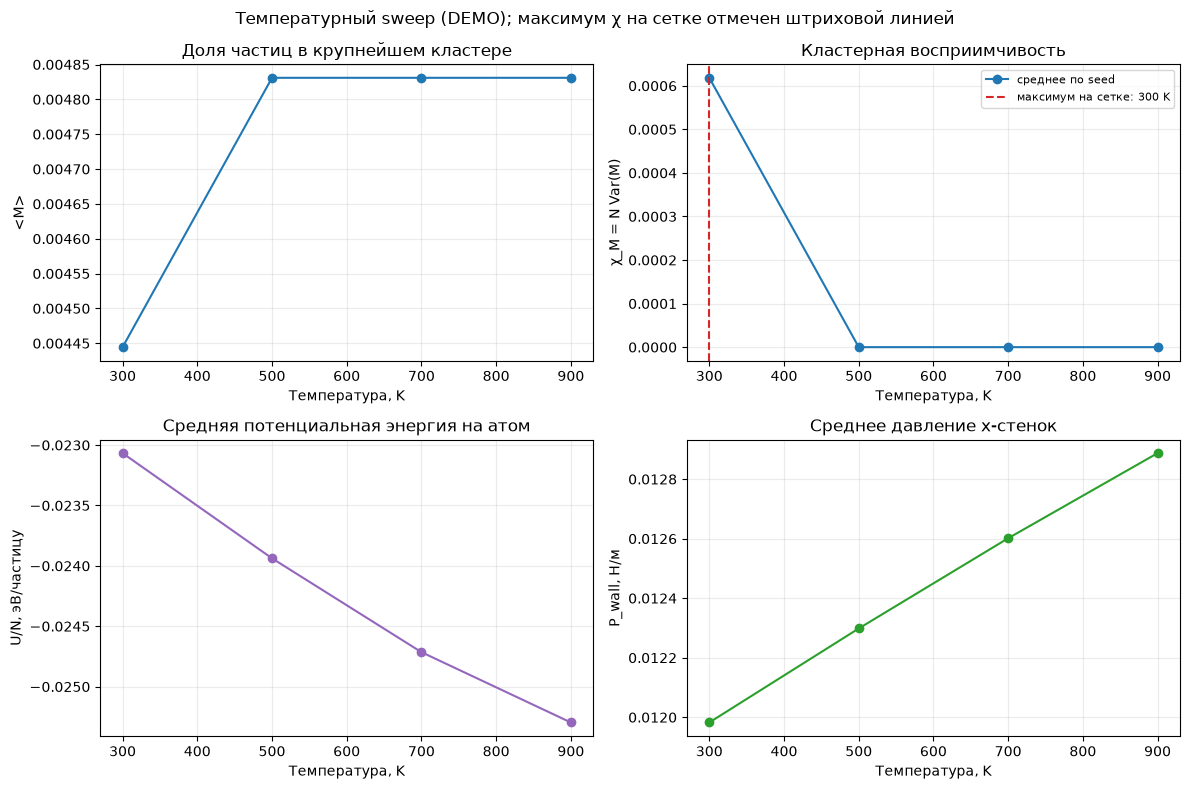

In [3]:
summary = []
for temperature in TEMPERATURES:
    group = [row for row in results if row['T'] == temperature]
    summary.append({'T': temperature,
        'M_mean': float(np.mean([row['largest_cluster_mean'] for row in group])),
        'chi_mean': float(np.mean([row['cluster_susceptibility'] for row in group])),
        'U_per_K': float(np.mean([row['potential_energy_per_particle'] for row in group])),
        'P_wall': float(np.mean([row['P_eq'] for row in group])),
        'chi_seed_std': float(np.std([row['cluster_susceptibility'] for row in group], ddof=1)) if len(group) > 1 else np.nan,
        'P_seed_std': float(np.std([row['P_eq'] for row in group], ddof=1)) if len(group) > 1 else np.nan})
transition_index = int(np.argmax([row['chi_mean'] for row in summary]))
transition_temperature = summary[transition_index]['T']

table_lines = ['| T, K | <M> | χ_M | U/N, Дж/частицу | P стенки, Н/м | SD χ между seed |', '|---:|---:|---:|---:|---:|---:|']
for row in summary:
    chi_sd = '—' if np.isnan(row['chi_seed_std']) else f"{row['chi_seed_std']:.3g}"
    table_lines.append(f"| {row['T']:.0f} | {row['M_mean']:.4f} | {row['chi_mean']:.4g} | {row['U_per_K']:.4e} | {row['P_wall']:.4e} | {chi_sd} |")
display(Markdown('\n'.join(table_lines)))

temperature_values = np.asarray([row['T'] for row in summary])
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].plot(temperature_values, [r['M_mean'] for r in summary], 'o-')
axes[0, 0].set(title='Доля частиц в крупнейшем кластере', xlabel='Температура, K', ylabel='<M>')
axes[0, 1].plot(temperature_values, [r['chi_mean'] for r in summary], 'o-', label='среднее по seed')
chi_errors = np.asarray([r['chi_seed_std'] for r in summary])
if len(SEEDS) > 1: axes[0, 1].errorbar(temperature_values, [r['chi_mean'] for r in summary], yerr=chi_errors, fmt='none', capsize=3, color='black', label='SD между seed')
axes[0, 1].axvline(transition_temperature, color='tab:red', linestyle='--', label=f'максимум на сетке: {transition_temperature:.0f} K')
axes[0, 1].set(title='Кластерная восприимчивость', xlabel='Температура, K', ylabel='χ_M = N Var(M)'); axes[0, 1].legend(fontsize=8)
axes[1, 0].plot(temperature_values, [r['U_per_K'] / 1.602176634e-19 for r in summary], 'o-', color='tab:purple')
axes[1, 0].set(title='Средняя потенциальная энергия на атом', xlabel='Температура, K', ylabel='U/N, эВ/частицу')
axes[1, 1].plot(temperature_values, [r['P_wall'] for r in summary], 'o-', color='tab:green')
axes[1, 1].set(title='Среднее давление x-стенок', xlabel='Температура, K', ylabel='P_wall, Н/м')
for axis in axes.flat: axis.grid(alpha=0.25)
fig.suptitle(f'Температурный sweep ({MODE}); максимум χ на сетке отмечен штриховой линией')
fig.tight_layout(); plt.show()


### Интерпретация, диапазон и неопределённость

Газоподобное поведение ожидается при меньшей средней доле крупнейшего кластера; при охлаждении доля и притяжательная энергия могут указывать на объединение частиц. Пик $\chi_M$ показывает температуры, где флуктуации кластера максимальны, и служит выбранным структурным маркером. При грубой сетке можно назвать только температурную точку сетки и интервал между соседними исследованными значениями как разрешение поиска. Если максимум на краю диапазона, sweep не локализовал его — нужно расширить диапазон, а не экстраполировать.

Seed-to-seed разброс показывает чувствительность к начальным условиям; временные выборки внутри одного seed также коррелированы. Для более сильного вывода нужны больше независимых начальных состояний, длиннее equilibration/production, более мелкий шаг температуры, анализ размера системы и проверка кластерного порога. Температура определяется рескейлингом при подготовке, а не непрерывно поддерживается в production. Ни точность до одного значения T, ни кипение реального K эти вычисления не устанавливают.

In [4]:
output_dir = PROJECT_ROOT / 'output' / 'notebooks' / 'task4_phase'
output_dir.mkdir(parents=True, exist_ok=True)
names = list(results[0])
np.savetxt(output_dir / 'phase_sweep.csv', np.asarray([[row[name] for name in names] for row in results]), delimiter=',', header=','.join(names), comments='')
if len(SEEDS) > 1:
    transition_by_seed = []
    for seed in SEEDS:
        seed_rows = [row for row in results if row['seed'] == seed]
        transition_by_seed.append(max(seed_rows, key=lambda row: row['cluster_susceptibility'])['T'])
    seed_range = f'{min(transition_by_seed):.0f}–{max(transition_by_seed):.0f} K (разброс оценок по seed)'
else:
    seed_range = 'не оценён: в запуске только один seed'
edge_note = 'Максимум на краю сетки: диапазон недостаточен для локализации.' if transition_index in (0, len(summary)-1) else 'Максимум расположен внутри исследованной сетки.'
display(Markdown(f'**Итог ({MODE}):** максимум кластерной восприимчивости получен при T = {transition_temperature:.0f} K на выбранной сетке. {edge_note} Диапазон оценок seed: {seed_range}. Это структурный crossover данной конечной 2D LJTS-модели, а не экспериментальная температура фазового перехода калия. Параметры: {len(TEMPERATURES)} температур, {len(SEEDS)} seed, термализация {EQUIL_STEPS} шагов и production {PRODUCTION_STEPS} шагов на точку.'))
print(f'Результаты CSV: {output_dir.relative_to(PROJECT_ROOT) / "phase_sweep.csv"}')


**Итог (DEMO):** максимум кластерной восприимчивости получен при T = 300 K на выбранной сетке. Максимум на краю сетки: диапазон недостаточен для локализации. Диапазон оценок seed: не оценён: в запуске только один seed. Это структурный crossover данной конечной 2D LJTS-модели, а не экспериментальная температура фазового перехода калия. Параметры: 4 температур, 1 seed, термализация 50 шагов и production 100 шагов на точку.

Результаты CSV: output/notebooks/task4_phase/phase_sweep.csv


## Возможные вопросы преподавателя

1. **Чем газ отличается от конденсированного состояния в этой диагностике?** В газоподобном режиме кластеры обычно меньше и доля крупнейшего кластера ниже; при притяжении формируется крупное объединение.
2. **Почему в двумерной конечной системе переход размыт?** Размер конечен, флуктуации существенны, а строгие термодинамические особенности формируются в пределе бесконечной системы.
3. **Зачем стенки x и PBC y?** Это модель щели: стенки ограничивают поперечное движение, периодичность устраняет края вдоль канала.
4. **Что такое температурный sweep?** Набор расчётов в разных условиях температуры для построения зависимостей observables от T.
5. **Как термостатируется система?** Перед production каждые 10 шагов скорости масштабируются на $\sqrt{T_{target}/T_{measured}}$; после этого термостат выключен.
6. **Как определён кластер?** Частицы связываются ребром, если расстояние меньше $1.5\sigma$; связные компоненты находятся объединением пар.
7. **Что показывает $\chi_M$?** Насколько сильно флуктуирует доля крупнейшего кластера; пик используется как модельная метка crossover.
8. **Зачем несколько seed?** Они показывают вариацию из-за начальных координат и скоростей, которую один запуск не оценивает.
9. **Почему нельзя назвать найденное T точкой кипения калия?** Из-за конечной 2D геометрии, упрощённого LJ-потенциала, фиксированных стенок и структурного, а не термодинамического критерия.
10. **Как уточнить результат?** Увеличить число seed и длину траектории, уменьшить температурный шаг, исследовать несколько N/размеров и проверить зависимость от критерия кластера.